# Step 7: Boosting (AdaBoost and Gradient Boosting)

**Idea:** boosting builds many small decision trees one after another, each trying to fix the mistakes of the ones
before it. We test whether this gives better drift robustness than the Step 5 baselines.

- **AdaBoost:** 100 rounds of depth-1 trees (library default weak learner).
- **Gradient Boosting:** 100 trees of depth 3, learning rate 0.1.
- Each is run with no reduction, with PCA and with LDA (as in Step 6), on protocols A, B and C.
- Settings are fixed in advance. **Nothing is tuned and no test batch is used to choose anything** (tuning is Step 8).
- The scaler and any reducer are fitted on training batches only.

In [1]:
import os
import sys
import time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import data_loader as dl
from src import evaluation as ev
from src import models

pd.set_option("display.width", 170)
df = dl.remove_toluene(dl.load_all())
BOOST = models.BOOSTING_NAMES
BASE = models.BASELINE_NAMES
RED = ["None", "PCA", "LDA"]
Path("../results/models").mkdir(parents=True, exist_ok=True)

# earlier results (baselines): Step 5 = no reduction, Step 6 = PCA and LDA
s5 = pd.read_csv("../results/step5_baseline_metrics.csv"); s5["reduction"] = "None"
s6 = pd.read_csv("../results/step6_reduction_metrics.csv"); s6 = s6[s6["reduction"] != "None"]
earlier = pd.concat([s5, s6], ignore_index=True)
print("Earlier results:", earlier["model"].nunique(), "models x", earlier["reduction"].nunique(), "reductions")

Earlier results: 5 models x 3 reductions


## 1. Run the boosting models

In [2]:
runs, fit_seconds = [], {}
for red in RED:
    for name, make in models.get_boosting(red).items():
        parts = []
        t0 = time.perf_counter()
        m, _, fitted = ev.evaluate_split(make, df, ev.get_splits("A")[0], return_model=True)
        fit_seconds[(name, red)] = time.perf_counter() - t0
        parts.append(m)
        tag = "" if red == "None" else red.lower() + "_"
        joblib.dump(fitted, f"../results/models/{tag}{name.replace(' ', '_').lower()}_protocolA.joblib"
                    if red != "None" else f"../results/models/baseline_{name.replace(' ', '_').lower()}_protocolA.joblib")
        for p in "BC":
            parts.append(ev.run_protocol(make, df, p)[0])
        m_all = pd.concat(parts, ignore_index=True)
        m_all.insert(0, "model", name)
        m_all["reduction"] = red
        runs.append(m_all)
        print(f"{name:18s} {red:5s} done  (protocol A fit+predict {fit_seconds[(name, red)]:.1f}s)")

boost = pd.concat(runs, ignore_index=True)
boost.to_csv("../results/step7_boosting_metrics.csv", index=False)
allm = pd.concat([earlier, boost], ignore_index=True)

AdaBoost           None  done  (protocol A fit+predict 14.5s)


Gradient Boosting  None  done  (protocol A fit+predict 174.4s)


AdaBoost           PCA   done  (protocol A fit+predict 0.9s)


Gradient Boosting  PCA   done  (protocol A fit+predict 7.5s)


AdaBoost           LDA   done  (protocol A fit+predict 0.6s)


Gradient Boosting  LDA   done  (protocol A fit+predict 3.4s)


## 2. Protocol A (headline)

In [3]:
A = allm[(allm["protocol"] == "A") & (allm["test_batch"] == "pooled")]
acc = A.pivot(index="model", columns="reduction", values="accuracy")[RED]
f1 = A.pivot(index="model", columns="reduction", values="macro_f1")[RED]
order = BASE + BOOST
table = pd.concat({"pooled accuracy": acc.loc[order], "pooled macro-F1": f1.loc[order]}, axis=1)
table.round(3).to_csv("../results/step7_protocolA_all_models.csv")
table.round(3)

pooled accuracy               pooled macro-F1              
reduction                    None    PCA    LDA            None    PCA    LDA
model                                                                        
kNN                         0.696  0.683  0.669           0.707  0.693  0.677
SVM                         0.727  0.670  0.661           0.740  0.695  0.672
Decision Tree               0.497  0.530  0.617           0.466  0.515  0.609
Random Forest               0.647  0.704  0.677           0.617  0.683  0.674
Naive Bayes                 0.565  0.521  0.716           0.567  0.509  0.716
AdaBoost                    0.472  0.712  0.610           0.452  0.683  0.622
Gradient Boosting           0.558  0.687  0.592           0.547  0.682  0.612

In [4]:
best = acc.stack().sort_values(ascending=False).head(6)
print("Top 6 model/reduction combinations by pooled accuracy (protocol A):")
print(best.round(3).to_string())

Top 6 model/reduction combinations by pooled accuracy (protocol A):
model              reduction
SVM                None         0.727
Naive Bayes        LDA          0.716
AdaBoost           PCA          0.712
Random Forest      PCA          0.704
kNN                None         0.696
Gradient Boosting  PCA          0.687


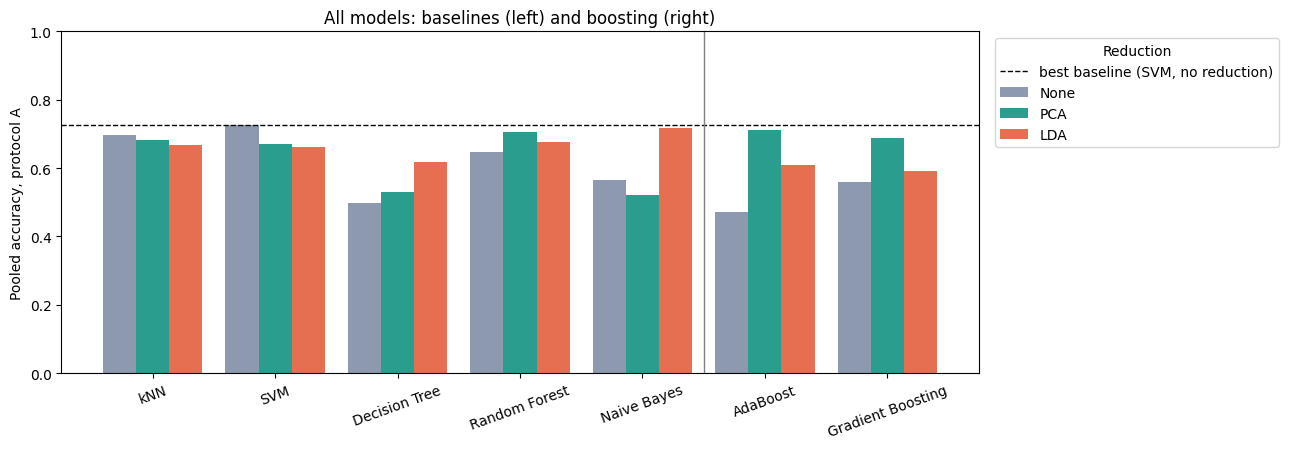

In [5]:
colors = {"None": "#8d99ae", "PCA": "#2a9d8f", "LDA": "#e76f51"}
fig, ax = plt.subplots(figsize=(13, 4.6))
x = np.arange(len(order))
for i, r in enumerate(RED):
    ax.bar(x + (i - 1) * 0.27, acc.loc[order, r], 0.27, label=r, color=colors[r])
ax.axhline(acc.loc["SVM", "None"], color="black", ls="--", lw=1, label="best baseline (SVM, no reduction)")
ax.axvline(len(BASE) - 0.5, color="grey", lw=1)
ax.set_xticks(x); ax.set_xticklabels(order, rotation=20)
ax.set_ylim(0, 1); ax.set_ylabel("Pooled accuracy, protocol A")
ax.set_title("All models: baselines (left) and boosting (right)")
ax.legend(title="Reduction", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig("../results/step7_protocolA_all.png", dpi=150)
plt.show()

**What to notice (protocol A, pooled accuracy, single run, untuned):**

| Model | None | PCA | LDA |
|---|---|---|---|
| AdaBoost | 47.2% | **71.2%** (+24.0) | 61.0% (+13.8) |
| Gradient Boosting | 55.8% | 68.7% (+12.9) | 59.2% (+3.4) |
| *best baseline: SVM, no reduction* | *72.7%* | | |

- **Boosting does not beat the best baseline.** The best boosting result is AdaBoost + PCA at 71.2%, which is 1.5 points
  below SVM (72.7%); its macro-F1 is 68.3% against SVM's 74.0%.
- **Without reduction, boosting is weak under drift:** AdaBoost (47.2%) is about as low as a single Decision Tree
  (49.7%), and Gradient Boosting (55.8%) is below Random Forest (64.7%) and kNN (69.6%).
- **PCA helps both boosters a lot, and LDA helps less.** A plausible reason is that trees split on single raw
  features, which are sensitive to drift, and PCA mixes the features first. We did not test this explanation.
- **Top 6 combinations:** SVM (72.7%), Naive Bayes + LDA (71.6%), AdaBoost + PCA (71.2%), Random Forest + PCA (70.4%),
  kNN (69.6%), Gradient Boosting + PCA (68.7%). The gaps among these are small and not tested for significance.

In [6]:
pb = allm[(allm["protocol"] == "A") & (allm["test_batch"] != "pooled") & (allm["reduction"] == "None")].copy()
pb["test_batch"] = pb["test_batch"].astype(int)
accb = pb.pivot(index="test_batch", columns="model", values="accuracy")
print("Per-batch accuracy, no reduction (protocol A)")
accb[["SVM", "Random Forest"] + BOOST].round(3)

Per-batch accuracy, no reduction (protocol A)


model,SVM,Random Forest,AdaBoost,Gradient Boosting
test_batch,,,,
4,0.876,0.870,0.646,0.702
5,0.954,0.756,0.442,0.939
6,0.871,0.911,0.700,0.673
7,0.812,0.703,0.410,0.615
8,0.587,0.348,0.500,0.341
9,0.946,0.678,0.526,0.480
10,0.517,0.435,0.380,0.427


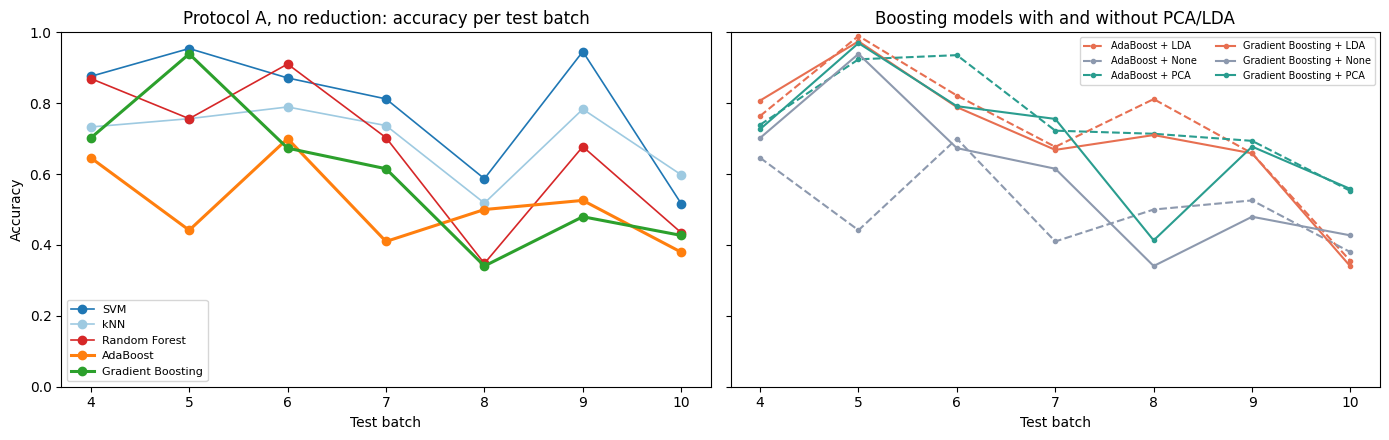

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
palette = {"SVM": "#1f77b4", "kNN": "#9ecae1", "Random Forest": "#d62728", "AdaBoost": "#ff7f0e", "Gradient Boosting": "#2ca02c"}
for n in ["SVM", "kNN", "Random Forest"] + BOOST:
    axes[0].plot(accb.index, accb[n], marker="o", color=palette[n], label=n, lw=2.2 if n in BOOST else 1.2)
axes[0].set_title("Protocol A, no reduction: accuracy per test batch")
axes[0].set_xlabel("Test batch"); axes[0].set_ylabel("Accuracy"); axes[0].set_ylim(0, 1); axes[0].legend(fontsize=8)

pbl = allm[(allm["protocol"] == "A") & (allm["test_batch"] != "pooled") & (allm["model"].isin(BOOST))].copy()
pbl["test_batch"] = pbl["test_batch"].astype(int)
for (n, r), g in pbl.groupby(["model", "reduction"]):
    axes[1].plot(g["test_batch"], g["accuracy"], marker="o", ms=3, color=colors[r],
                 ls="-" if n == "Gradient Boosting" else "--", label=f"{n} + {r}")
axes[1].set_title("Boosting models with and without PCA/LDA"); axes[1].set_xlabel("Test batch")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("../results/step7_per_batch.png", dpi=150)
plt.show()

**What to notice:**
- **Left (no reduction):** SVM beats both boosting models on every test batch. The widest gap is batch 9 (SVM 94.6%,
  Gradient Boosting 48.0%, AdaBoost 52.6%). Gradient Boosting is competitive only on batch 5 (93.9% vs 95.4%).
- **Right (with PCA/LDA):** boosting models do better, and some beat SVM on individual batches:
  on batch 10, AdaBoost + PCA (55.2%) and Gradient Boosting + PCA (55.8%) beat SVM (51.7%); on batch 8,
  AdaBoost + LDA reaches 81.2% against SVM's 58.7%; on batch 6, AdaBoost + PCA gets 93.6% against 87.1%.
- **But LDA collapses on batch 10** (AdaBoost 35.5%, Gradient Boosting 33.9%), the same pattern as Step 6.
- SVM stays ahead overall because it is much better on batches 7 and 9, and batches 7 and 10 carry 68% of the
  test samples.

## 3. Protocols B and C (supporting)

In [8]:
rows = {}
for p in "BC":
    d = allm[allm["protocol"] == p].copy()
    d["test_batch"] = d["test_batch"].astype(int)
    rows[f"{p} mean accuracy"] = d.groupby(["model", "reduction"])["accuracy"].mean().unstack()[RED].loc[order]
bc = pd.concat(rows, axis=1)
bc.round(3).to_csv("../results/step7_protocolBC_all_models.csv")
bc.round(3)

B mean accuracy               C mean accuracy              
reduction                    None    PCA    LDA            None    PCA    LDA
model                                                                        
kNN                         0.407  0.468  0.331           0.826  0.820  0.828
SVM                         0.430  0.451  0.279           0.872  0.860  0.840
Decision Tree               0.551  0.510  0.433           0.743  0.748  0.796
Random Forest               0.506  0.535  0.378           0.848  0.817  0.820
Naive Bayes                 0.528  0.351  0.378           0.558  0.666  0.830
AdaBoost                    0.379  0.468  0.377           0.639  0.774  0.835
Gradient Boosting           0.542  0.420  0.280           0.801  0.835  0.803

**What to notice:**
- **Protocol B (train on batch 1 only):** Gradient Boosting with no reduction averages 54.2%, which is close to the
  best in that protocol (Decision Tree 55.1%); AdaBoost is weak (37.9%). PCA and LDA lower Gradient Boosting here
  (42.0% and 28.0%) but raise AdaBoost with PCA (46.8%). With only 371 training samples these results are noisy.
- **Protocol C (retrain on all earlier batches):** SVM remains best (87.2%). Boosting with reduction is close behind:
  AdaBoost + LDA 83.5%, Gradient Boosting + PCA 83.5%. Without reduction, Gradient Boosting reaches 80.1% and
  AdaBoost 63.9%.

So boosting only becomes competitive when it gets either recent labelled data (C) or PCA/LDA features (A).

In [9]:
print("Protocol A fit + predict time (seconds):")
pd.Series(fit_seconds).unstack().round(1)

Protocol A fit + predict time (seconds):


,LDA,None,PCA
AdaBoost,0.6,14.5,0.9
Gradient Boosting,3.4,174.4,7.5


**What to notice:** Gradient Boosting on all 128 features took between 2 and 3 minutes in our runs (124 s and 174 s),
against under 10 s with PCA or LDA, so reduction also makes boosting more than ten times faster. Exact timings vary
from run to run; the accuracy results do not.

## Summary of Step 7
- **Boosting did not beat the best baseline.** Best boosting: AdaBoost + PCA, 71.2% pooled accuracy (macro-F1 68.3%);
  best baseline: SVM, 72.7% (macro-F1 74.0%).
- On the raw features boosting is weak under drift (AdaBoost 47.2%, Gradient Boosting 55.8%). PCA improves both by
  13 to 24 points; LDA improves them less and fails on batch 10.
- Some boosting + reduction combinations beat SVM on individual batches (6, 8, 10) but lose on batches 7 and 9, which
  decides the pooled result.
- Single runs, default settings, no confidence intervals yet; Step 8 tunes with training batches only and Step 10 adds
  confidence intervals.